# Texas Bridge Condition Regression

This notebook evaluates how age, traffic, truck share, material and design are associated with a composite condition score in a prepared sample from the 2019 National Bridge Inventory. The analysis emphasizes reproducibility, out-of-sample evaluation and sensitivity to bridge exclusions.

## Questions

1. Which proposed predictors have the strongest fitted associations with bridge condition?
2. How accurately does an interpretable linear model predict unseen records?
3. Do the conclusions change when bridges aged 80 or older and historically registered bridges are retained?

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.bridge_analysis import (
    ALL_COMPLETE,
    FILTERED_SCOPE,
    coefficient_table,
    continuous_range_effects,
    load_bridge_data,
    prepare_bridge_data,
    sensitivity_analysis,
    validate_bridge_data,
)

sns.set_theme(style='whitegrid', context='notebook')
pd.options.display.float_format = '{:,.4f}'.format
DATA_PATH = PROJECT_ROOT / 'data' / 'raw' / 'tx19_bridges_sample.csv'

## 1 Source validation

The raw CSV remains unchanged. The checks below validate its dimensions, identifiers, rating labels, missing values and construction-year range.

In [2]:
raw = load_bridge_data(DATA_PATH)
source_summary = pd.Series(validate_bridge_data(raw), name='Value')
source_summary.to_frame()

,Value
rows,34293
columns,25
duplicate_structure_ids,0
missing_deck_ratings,5
missing_superstructure_ratings,2
missing_substructure_ratings,0
minimum_year_built,1900
maximum_year_built,2019


In [3]:
missing_ratings = raw[['Deck_rating', 'Superstr_rating', 'Substr_rating']].isna().sum()
missing_ratings.rename('Missing records').to_frame()

,Missing records
Deck_rating,5
Superstr_rating,2
Substr_rating,0


Seven records lack a deck or superstructure rating. They cannot receive the complete composite target and are removed from both analysis scopes.

## 2 Feature and target construction

The source field `Year` represents year built. Age is therefore calculated relative to the 2019 data vintage. The three component ratings are mapped from Failed=0 through Excellent=9 and summed into a 0-27 condition score.

In [4]:
all_complete = prepare_bridge_data(raw, scope=ALL_COMPLETE)
filtered = prepare_bridge_data(raw, scope=FILTERED_SCOPE)

scope_counts = pd.DataFrame({
    'Scope': ['Source sample', 'Complete records', 'Under 80 and non-Register'],
    'Records': [len(raw), len(all_complete), len(filtered)],
})
scope_counts

,Scope,Records
0,Source sample,34293
1,Complete records,34286
2,Under 80 and non-Register,31905


In [5]:
filtered[['Age', 'AverageDaily', 'Trucks_percent', 'Current_Condition']].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,"31,905.0000",33.8397,20.2854,0.0000,16.0000,32.0000,51.0000,79.0000
AverageDaily,"31,905.0000","12,133.6113","24,961.2839",0.0000,330.0000,"3,420.0000","12,410.0000","543,000.0000"
Trucks_percent,"31,905.0000",8.3929,10.2915,0.0000,0.0000,5.0000,13.0000,99.0000
Current_Condition,"31,905.0000",20.4360,1.9409,0.0000,19.0000,21.0000,22.0000,27.0000


The restricted scope excludes bridges aged 80 or older and bridges listed on the historic register. The complete-record model below provides a sensitivity check rather than assuming the exclusion has no effect.

## 3 Exploratory analysis

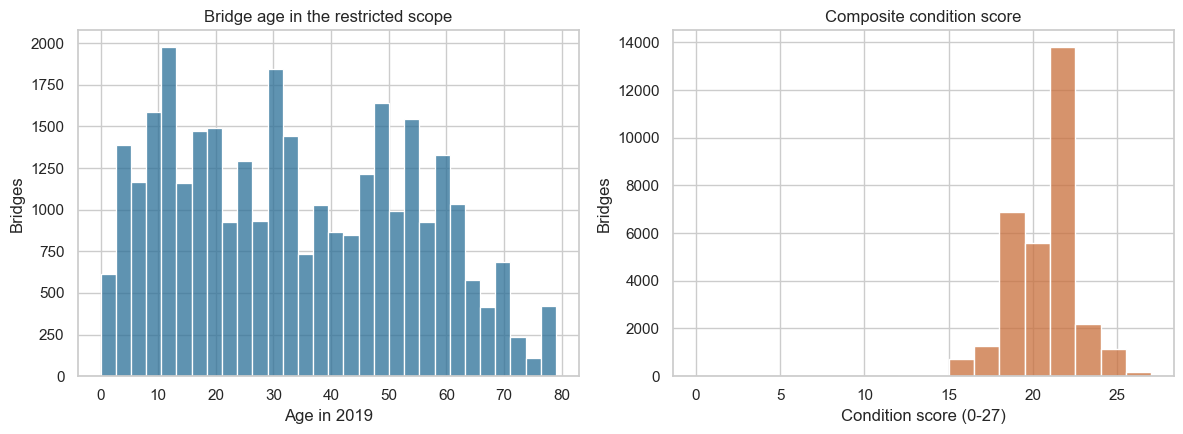

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(filtered['Age'], bins=30, ax=axes[0], color='#2A6F97')
axes[0].set(title='Bridge age in the restricted scope', xlabel='Age in 2019', ylabel='Bridges')
sns.histplot(filtered['Current_Condition'], bins=18, ax=axes[1], color='#C96F3B')
axes[1].set(title='Composite condition score', xlabel='Condition score (0-27)', ylabel='Bridges')
plt.tight_layout()
plt.show()

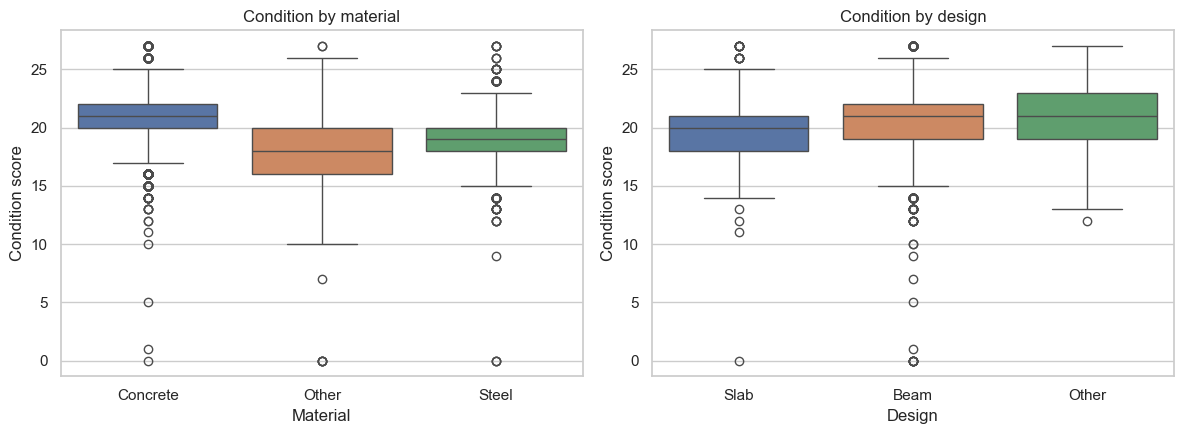

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=filtered, x='Material', y='Current_Condition', ax=axes[0], hue='Material', legend=False)
axes[0].set(title='Condition by material', xlabel='Material', ylabel='Condition score')
sns.boxplot(data=filtered, x='Design', y='Current_Condition', ax=axes[1], hue='Design', legend=False)
axes[1].set(title='Condition by design', xlabel='Design', ylabel='Condition score')
plt.tight_layout()
plt.show()

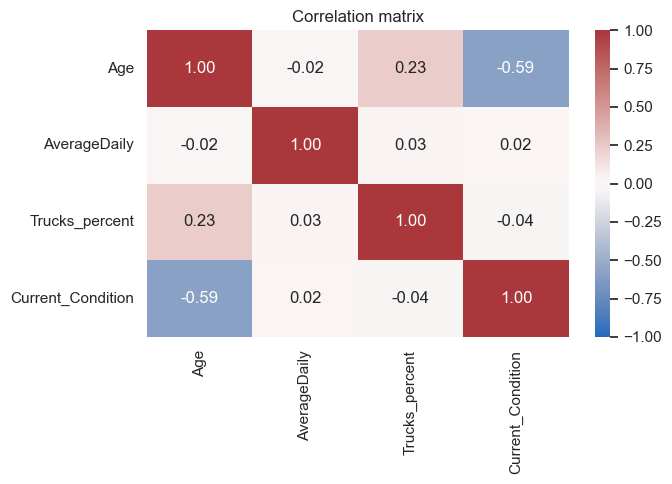

In [8]:
correlations = filtered[['Age', 'AverageDaily', 'Trucks_percent', 'Current_Condition']].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

Age has the clearest bivariate association with condition. Material groups also differ, while traffic and truck share show weak linear relationships. These plots are descriptive and do not adjust for the other predictors.

## 4 Out-of-sample model evaluation

Both scopes use the same ordinary least-squares specification. Material and design are one-hot encoded, 20% of records are held out using random state 42, and five shuffled folds estimate cross-validated performance.

In [9]:
comparison, results = sensitivity_analysis(raw, random_state=42)
display_columns = [
    'scope', 'observations', 'holdout_r2', 'holdout_rmse', 'holdout_mae',
    'cv_r2_mean', 'cv_r2_sd', 'cv_rmse_mean', 'cv_rmse_sd',
]
comparison[display_columns]

,scope,observations,holdout_r2,holdout_rmse,holdout_mae,cv_r2_mean,cv_r2_sd,cv_rmse_mean,cv_rmse_sd
0,all_complete,34286,0.4548,1.4694,1.0953,0.4505,0.0146,1.4858,0.0285
1,under_80_nonhistoric,31905,0.4556,1.4336,1.0751,0.4552,0.0155,1.4324,0.0359


The restricted model explains approximately 45.5% of unseen variation and has a cross-validated RMSE of approximately 1.43 condition points. Including older and historically registered bridges changes R² only slightly.

## 5 Coefficient interpretation

In [10]:
filtered_result = results[FILTERED_SCOPE]
coefficients = coefficient_table(filtered_result)
coefficients

,Predictor,Coefficient
0,Material: Other,-2.8408
1,Material: Steel,-1.3812
4,Age,-0.0556
5,AverageDaily,-0.0000
6,Trucks_percent,0.0055
3,Design: Slab,0.0467
2,Design: Other,0.0720


In [11]:
range_effects = continuous_range_effects(filtered, filtered_result)
range_effects

,Predictor,10th-90th range,Condition-point effect,Percent of target range
0,Age,53.0000,-2.9484,-58.9673
1,AverageDaily,"30,700.0000",-0.0067,-0.1342
2,Trucks_percent,23.0000,0.1258,2.5162


The filtered model estimates a 0.0556-point decrease in condition for each additional year of age. Across the observed 10th-to-90th percentile age range, the fitted difference is approximately 2.95 points. Relative to concrete, steel is associated with a 1.38-point lower score and the mixed `Other` material group with a 2.84-point lower score. Traffic, truck share and design have comparatively small fitted differences.

## 6 Holdout diagnostics

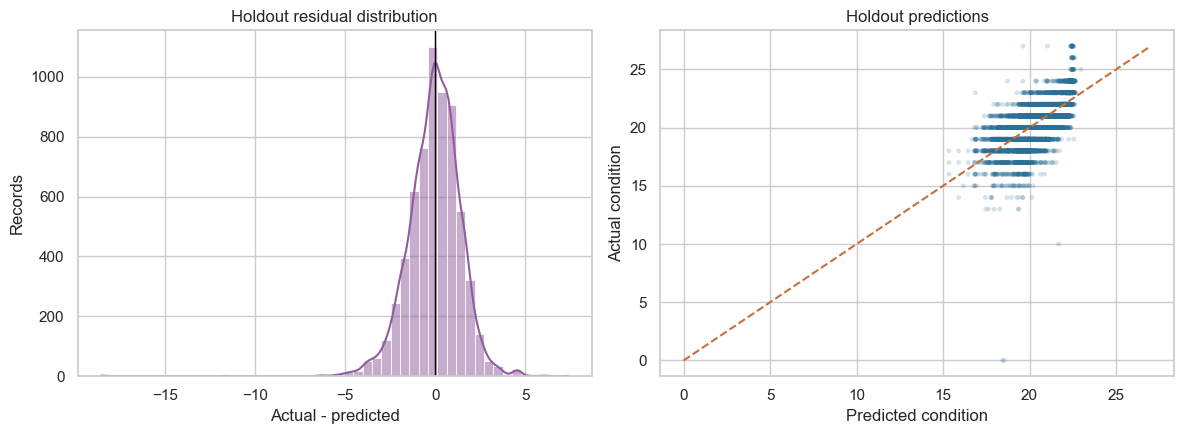

Residual mean                 -0.0387
Residual standard deviation    1.4332
Residual skew                 -0.9443
dtype: float64

In [12]:
residuals = filtered_result.holdout_residuals
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(residuals, bins=50, kde=True, ax=axes[0], color='#8F5D9F')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set(title='Holdout residual distribution', xlabel='Actual - predicted', ylabel='Records')
axes[1].scatter(
    filtered_result.holdout_predicted,
    filtered_result.holdout_actual,
    alpha=0.20, s=12, color='#2A6F97', edgecolors='none'
)
low = min(filtered_result.holdout_predicted.min(), filtered_result.holdout_actual.min())
high = max(filtered_result.holdout_predicted.max(), filtered_result.holdout_actual.max())
axes[1].plot([low, high], [low, high], color='#C96F3B', linestyle='--')
axes[1].set(title='Holdout predictions', xlabel='Predicted condition', ylabel='Actual condition')
plt.tight_layout()
plt.show()

pd.Series({
    'Residual mean': residuals.mean(),
    'Residual standard deviation': residuals.std(ddof=1),
    'Residual skew': pd.Series(residuals).skew(),
})

Residuals remain negatively skewed and the model compresses predictions toward the centre of the score distribution. The linear specification is a useful interpretable baseline, but it does not capture every low-condition bridge accurately.

## Conclusions

- Age and material have the strongest fitted associations with the composite condition score.
- Average daily traffic, truck share and design add little linear predictive information in this specification.
- Five-fold results are close to holdout performance, with R² near 0.45 and RMSE near 1.4 points.
- Including older and historically registered bridges does not materially change the main conclusion.
- The results are predictive associations, not causal evidence for maintenance or material-selection decisions.

## Limitations

The prepared file is a simplified subset of the 2019 Texas inventory. The target sums three ordinal ratings with equal weight, the model is cross-sectional, and important factors such as reconstruction year, maintenance history, environment and loading history are unavailable. The `Other` material category is heterogeneous, and the residual distribution shows that a linear model is not a complete representation of bridge deterioration.